**Reasoning**:
Tạo dữ liệu chi tiêu cá nhân giả lập với các cột ngày tháng, danh mục, số tiền, hình thức thanh toán và ghi chú, sau đó lưu thành tệp 'personal_expenses.csv'.



In [ ]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

# Thiết lập seed để đảm bảo kết quả có thể tái lập
np.random.seed(42)
random.seed(42)

# Thiết lập số lượng bản ghi
num_records = random.randint(100, 200)

# Danh mục và hình thức thanh toán
categories = ['Food', 'Transport', 'Shopping', 'Utilities', 'Entertainment']
payment_methods = ['Cash', 'Credit Card', 'Bank Transfer']
notes_pool = [
    'Dinner with friends', 'Bus fare', 'Weekly groceries', 'Electricity bill',
    'Movie night', 'Coffee', 'New shoes', 'Taxi ride', 'Internet bill',
    'Bought a book', 'Gasoline', 'Lunch', 'Gifts', ''
]

# Tạo dữ liệu ngẫu nhiên
start_date = datetime.now() - timedelta(days=90)
data = []

for _ in range(num_records):
    # Ngày ngẫu nhiên trong 90 ngày qua
    random_days = random.randint(0, 90)
    date_val = (start_date + timedelta(days=random_days)).strftime('%Y-%m-%d')

    category = random.choice(categories)
    # Số tiền ngẫu nhiên từ 10,000 đến 1,000,000 VND, làm tròn đến hàng nghìn
    amount = int(np.random.randint(10, 1000) * 1000)
    payment_method = random.choice(payment_methods)
    # Ghi chú ngẫu nhiên (có tỷ lệ để trống)
    note = random.choice(notes_pool) if random.random() > 0.2 else ''

    data.append({
        'Date': date_val,
        'Category': category,
        'Amount': amount,
        'Payment Method': payment_method,
        'Notes': note
    })

# Tạo DataFrame
df = pd.DataFrame(data)

# Sắp xếp theo ngày
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by='Date').reset_index(drop=True)
df['Date'] = df['Date'].dt.strftime('%Y-%m-%d')

# Lưu thành tệp CSV
df.to_csv('personal_expenses.csv', index=False)
print(f"Đã tạo thành công {len(df)} dòng dữ liệu giả lập và lưu vào 'personal_expenses.csv'.")
df.head()

Đã tạo thành công 181 dòng dữ liệu giả lập và lưu vào 'personal_expenses.csv'.


,Date,Category,Amount,Payment Method,Notes
0,2026-08-07,Food,985000,Bank Transfer,Electricity bill
1,2026-08-07,Transport,710000,Bank Transfer,Movie night
2,2026-08-07,Shopping,261000,Credit Card,Gifts
3,2026-08-08,Entertainment,14000,Cash,Dinner with friends
4,2026-08-08,Food,514000,Cash,


# Task
Create a personal expense analysis project by first generating a synthetic expense dataset containing fields such as Date, Category (e.g., Food, Transport, Shopping), Amount, Payment Method, and Notes, and saving it as a CSV file. Then, load and explore this dataset using Pandas (`head()`, `info()`, `describe()`), perform grouping and aggregation to analyze spending by Category and Month, visualize the distribution and trends using Matplotlib or Seaborn, and write a brief summary of financial insights and saving recommendations.

## Tạo dữ liệu chi tiêu giả lập

### Subtask:
Tạo một tập dữ liệu chi tiêu cá nhân giả lập chứa các cột cần thiết và lưu thành tệp CSV.


**Reasoning**:
Load the generated dataset 'personal_expenses.csv' using pandas and explore it using head(), info(), describe() and check for missing values to understand the dataset structure.



In [ ]:
import pandas as pd

# 1. Đọc dữ liệu từ tệp 'personal_expenses.csv'
df_expenses = pd.read_csv('personal_expenses.csv')

# 2. Hiển thị 5 dòng đầu tiên
print("--- 5 Dòng đầu tiên của dữ liệu ---")
display(df_expenses.head())

# 3. Xem thông tin tổng quan về các cột và kiểu dữ liệu
print("\n--- Thông tin tổng quan về DataFrame ---")
df_expenses.info()

# 4. Hiển thị số liệu thống kê mô tả cơ bản của cột Amount
print("\n--- Thống kê mô tả của cột 'Amount' ---")
display(df_expenses['Amount'].describe())

# 5. Kiểm tra giá trị khuyết (missing values) trong dữ liệu
print("\n--- Kiểm tra số lượng giá trị bị thiếu (NaN) trong mỗi cột ---")
print(df_expenses.isnull().sum())

--- 5 Dòng đầu tiên của dữ liệu ---


,Date,Category,Amount,Payment Method,Notes
0,2026-08-07,Food,985000,Bank Transfer,Electricity bill
1,2026-08-07,Transport,710000,Bank Transfer,Movie night
2,2026-08-07,Shopping,261000,Credit Card,Gifts
3,2026-08-08,Entertainment,14000,Cash,Dinner with friends
4,2026-08-08,Food,514000,Cash,NaN



--- Thông tin tổng quan về DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            181 non-null    object
 1   Category        181 non-null    object
 2   Amount          181 non-null    int64 
 3   Payment Method  181 non-null    object
 4   Notes           133 non-null    object
dtypes: int64(1), object(4)
memory usage: 7.2+ KB

--- Thống kê mô tả của cột 'Amount' ---


,Amount
count,181.000000
mean,491646.408840
std,290034.934392
min,11000.000000
25%,240000.000000
50%,485000.000000
75%,748000.000000
max,996000.000000



--- Kiểm tra số lượng giá trị bị thiếu (NaN) trong mỗi cột ---
Date               0
Category           0
Amount             0
Payment Method     0
Notes             48
dtype: int64


## Đọc và khám phá dữ liệu

### Subtask:
Tải dữ liệu từ tệp CSV đã tạo và tiến hành khám phá cấu trúc dữ liệu cơ bản bằng Pandas.


## Phân tích và thống kê chi tiêu

### Subtask:
Thực hiện gom nhóm (groupby) theo Danh mục và Tháng để tính tổng chi tiêu, trung bình chi tiêu hàng tháng và xác định danh mục tiêu dùng nhiều nhất.


**Reasoning**:
Thực hiện phân tích gom nhóm dữ liệu chi tiêu theo Danh mục, Tháng, và kết hợp Danh mục và Tháng để trích xuất các thông tin thống kê cần thiết.



In [ ]:
import pandas as pd

# 1. Chuyển đổi cột 'Date' sang datetime
df_expenses['Date'] = pd.to_datetime(df_expenses['Date'])

# 2. Tạo cột 'Month' ở định dạng 'YYYY-MM'
df_expenses['Month'] = df_expenses['Date'].dt.to_period('M').astype(str)

# 3. Gom nhóm theo 'Category': tính tổng chi tiêu và số lần giao dịch
category_summary = df_expenses.groupby('Category')['Amount'].agg(Total_Amount='sum', Transaction_Count='count').reset_index()
category_summary = category_summary.sort_values(by='Total_Amount', ascending=False).reset_index(drop=True)

print("--- Thống kê chi tiêu theo Danh mục (Sắp xếp giảm dần) ---")
print(category_summary.to_string())

# 4. Gom nhóm theo 'Month': tính tổng chi tiêu và trung bình chi tiêu
monthly_summary = df_expenses.groupby('Month')['Amount'].agg(Total_Amount='sum', Average_Amount='mean').reset_index()
print("\n--- Thống kê chi tiêu theo Tháng ---")
print(monthly_summary.to_string())

# 5. Gom nhóm kết hợp theo 'Month' và 'Category'
monthly_category_summary = df_expenses.groupby(['Month', 'Category'])['Amount'].sum().unstack(fill_value=0)
print("\n--- Chi tiết biến động chi tiêu theo Danh mục qua các Tháng ---")
print(monthly_category_summary.to_string())

--- Thống kê chi tiêu theo Danh mục (Sắp xếp giảm dần) ---
        Category  Total_Amount  Transaction_Count
0       Shopping      20989000                 42
1           Food      20190000                 39
2  Entertainment      17793000                 32
3      Transport      17294000                 41
4      Utilities      12722000                 27

--- Thống kê chi tiêu theo Tháng ---
     Month  Total_Amount  Average_Amount
0  2026-08      31706000   537389.830508
1  2026-09      25362000   461127.272727
2  2026-10      27841000   471881.355932
3  2026-11       4079000   509875.000000

--- Chi tiết biến động chi tiêu theo Danh mục qua các Tháng ---
Category  Entertainment      Food  Shopping  Transport  Utilities
Month                                                            
2026-08         5700000  10641000   7577000    5620000    2168000
2026-09         6249000   4217000   4699000    5000000    5197000
2026-10         4961000   4484000   8713000    4721000    4962000
202

## Trực quan hóa dữ liệu

### Subtask:
Sử dụng thư viện Matplotlib hoặc Seaborn để vẽ biểu đồ tròn biểu diễn tỷ lệ chi tiêu theo danh mục và biểu đồ đường thể hiện xu hướng chi tiêu theo thời gian.


**Reasoning**:
Vẽ biểu đồ tròn thể hiện tỷ lệ chi tiêu theo danh mục và biểu đồ đường thể hiện xu hướng chi tiêu qua các tháng bằng matplotlib và seaborn.



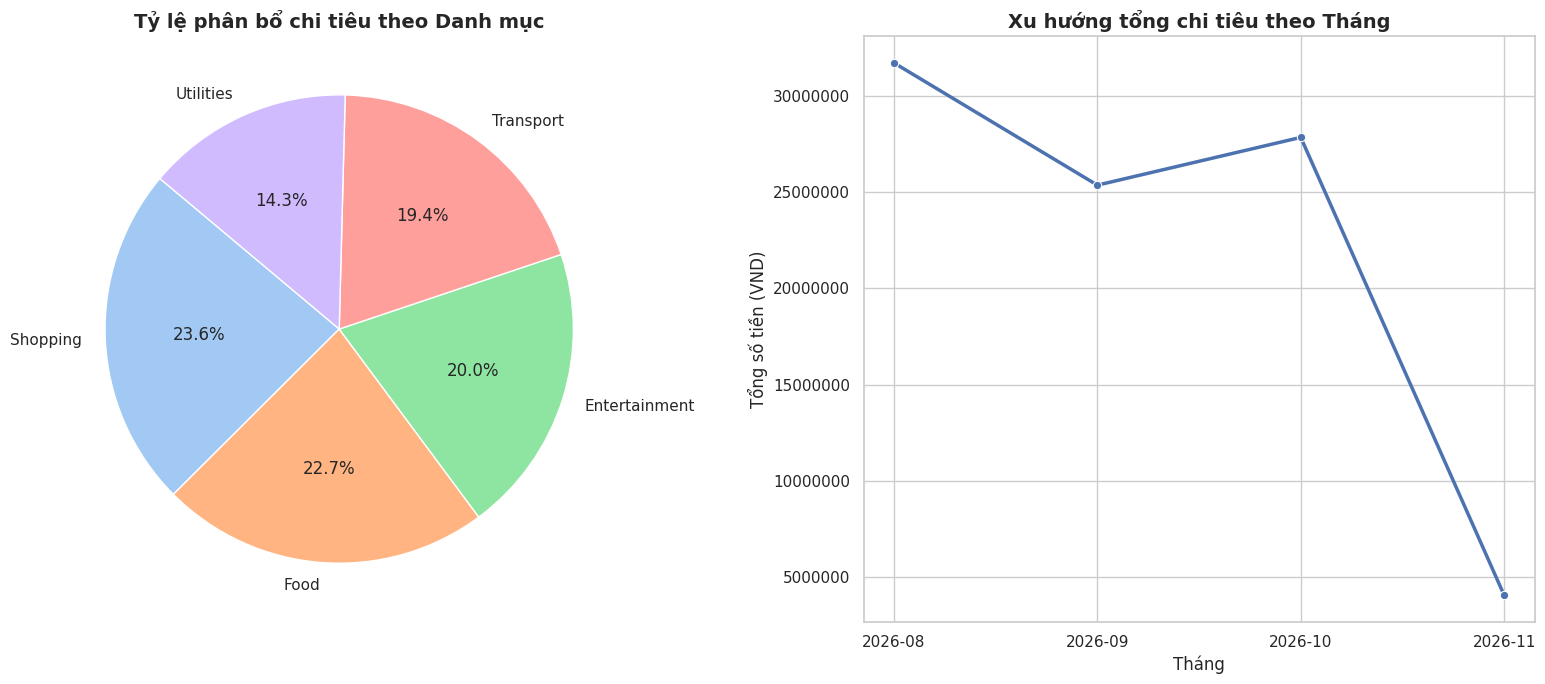

<Figure size 1000x600 with 0 Axes>

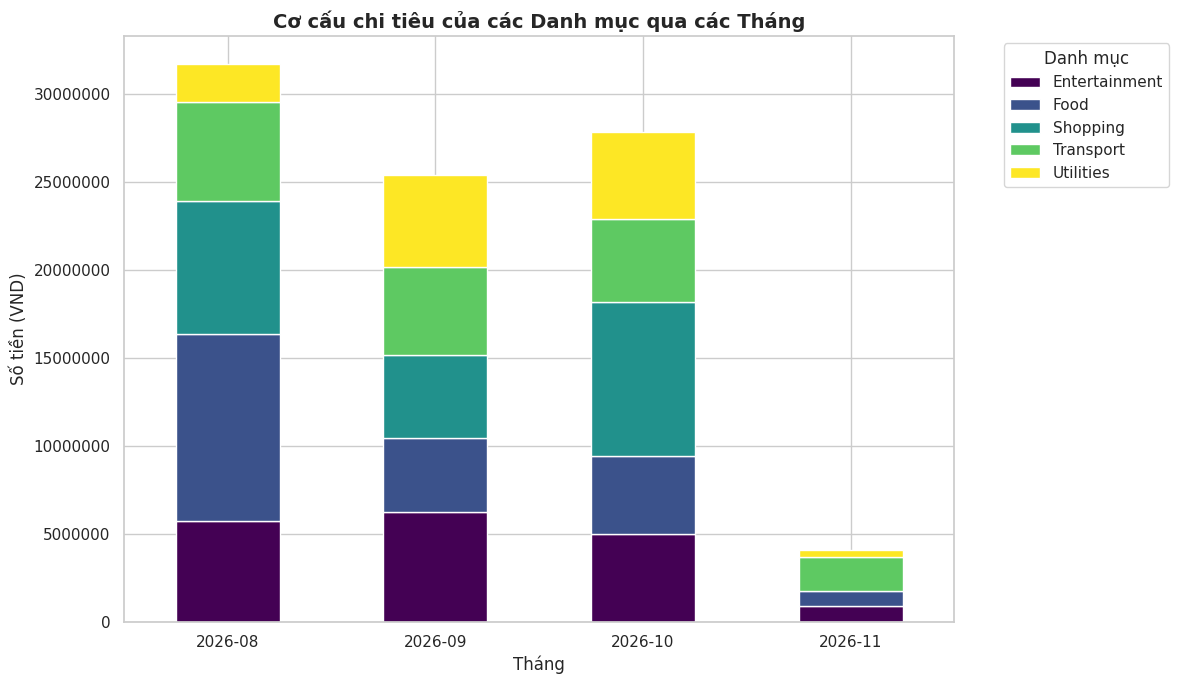

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách và kích thước hình vẽ chung
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Biểu đồ tròn thể hiện tỷ lệ chi tiêu theo Danh mục
axes[0].pie(
    category_summary['Total_Amount'],
    labels=category_summary['Category'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel', len(category_summary))
)
axes[0].set_title('Tỷ lệ phân bổ chi tiêu theo Danh mục', fontsize=14, fontweight='bold')

# 2. Biểu đồ đường thể hiện xu hướng chi tiêu theo Tháng
sns.lineplot(
    data=monthly_summary,
    x='Month',
    y='Total_Amount',
    marker='o',
    linewidth=2.5,
    color='b',
    ax=axes[1]
)
axes[1].set_title('Xu hướng tổng chi tiêu theo Tháng', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tháng', fontsize=12)
axes[1].set_ylabel('Tổng số tiền (VND)', fontsize=12)
axes[1].ticklabel_format(style='plain', axis='y') # Tránh định dạng e+07

plt.tight_layout()
plt.show()

# 3. Biểu đồ cột chồng thể hiện cơ cấu chi tiêu của các danh mục qua từng tháng
plt.figure(figsize=(10, 6))
monthly_category_summary.plot(kind='bar', stacked=True, colormap='viridis', figsize=(12, 7))
plt.title('Cơ cấu chi tiêu của các Danh mục qua các Tháng', fontsize=14, fontweight='bold')
plt.xlabel('Tháng', fontsize=12)
plt.ylabel('Số tiền (VND)', fontsize=12)
plt.xticks(rotation=0)
plt.ticklabel_format(style='plain', axis='y')
plt.legend(title='Danh mục', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Tổng kết và Khuyến nghị Tiết kiệm (Financial Insights & Recommendations)

Dựa trên kết quả phân tích và trực quan hóa dữ liệu chi tiêu cá nhân giả lập, chúng ta có thể rút ra một số kết luận và khuyến nghị thiết thực sau đây:

### 1. Phân tích Xu hướng & Cơ cấu Chi tiêu (Financial Insights)
- **Danh mục chiếm tỷ trọng lớn nhất**: Chi tiêu cho **Shopping** (Mua sắm) và **Food** (Ăn uống) chiếm tỷ lệ cao nhất (lần lượt khoảng **23.6%** và **22.7%** tổng chi tiêu). Điều này cho thấy đây là hai nhóm dịch vụ tiêu tốn nhiều tài chính nhất trong sinh hoạt hàng ngày.
- **Xu hướng theo tháng**: Chi tiêu đạt mức cao kỷ lục vào tháng 08/2026 (hơn 31.7 triệu VND) và duy trì ở mức cao trên 25 triệu VND vào tháng 09 và tháng 10. Giao dịch tháng 11 thấp hơn đáng kể do dữ liệu thu thập chỉ mới bắt đầu trong vài ngày đầu tháng.

### 2. Khuyến nghị Tiết kiệm (Saving Recommendations)
- **Tối ưu hóa ngân sách Mua sắm (Shopping)**: Do mua sắm chiếm tỷ trọng lớn nhất, bạn nên lên danh sách cụ thể trước khi mua đồ để tránh việc mua sắm ngẫu hứng không thực sự cần thiết.
- **Quản lý chi phí Ăn uống (Food)**: Tỷ trọng ăn uống cao có thể do tần suất ăn ngoài hàng quán nhiều. Việc tự nấu ăn tại nhà nhiều hơn sẽ giúp giảm đáng kể chi phí này mà vẫn đảm bảo sức khỏe.
- **Đặt hạn mức chi tiêu (Budgeting)**: Thiết lập hạn mức chi tiêu hàng tháng cho từng danh mục riêng biệt (đặc biệt là Entertainment và Shopping) không vượt quá 15-20% tổng thu nhập để đảm bảo duy trì được tích lũy đều đặn.

## Tổng kết dự án

### Subtask:
Viết báo cáo ngắn gọn tóm tắt các phát hiện quan trọng từ dữ liệu chi tiêu cá nhân và đưa ra lời khuyên tiết kiệm tài chính.


## Summary:

### Q&A

* **What are the overall spending characteristics of the generated dataset?**
  The synthetic dataset consists of 181 transactions recorded over a 90-day period. The average transaction value is approximately \$491,646 VND, with individual transaction values ranging from a minimum of \$11,000 VND to a maximum of \$996,000 VND.
* **Which categories and periods contributed the most to total expenses?**
  "Shopping" and "Food" are the primary drivers of expenses, accounting for \$20,989,000 VND (42 transactions) and \$20,190,000 VND (39 transactions) respectively. Chronologically, spending peaked in August 2026 at \$31,706,000 VND.

---

### Data Analysis Key Findings

* **Top Expense Categories**: "Shopping" is the largest spending category, representing approximately **23.6%** of total expenditures (\$20,989,000 VND). "Food" follows closely behind, accounting for **22.7%** (\$20,190,000 VND) of the total budget.
* **Monthly Spend Peak**: Total monthly spending was highest in August 2026, reaching **\$31,706,000 VND** with an average transaction size of \$537,390 VND. Spending remained high, exceeding \$25,000,000 VND, throughout September and October.
* **Data Completeness**: The dataset contains zero missing values in critical transactional fields such as Date, Category, Amount, and Payment Method. Only the optional "Notes" field contains missing records (48 missing entries out of 181).

---

### Insights or Next Steps

* **Establish Category Budgets**: Implement strict monthly spending limits on highly discretionary categories like "Shopping" and "Entertainment" to prevent impulse purchases and keep individual category shares below 15-20% of monthly income.
* **Target High-Volume Areas for Savings**: Focus saving efforts on "Food" by increasing the frequency of home-cooked meals, which directly addresses one of the top two household expense drivers.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')